In [ ]:
!pip install timm

<ipython-input-6-3cda22cc37a1>:171: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(


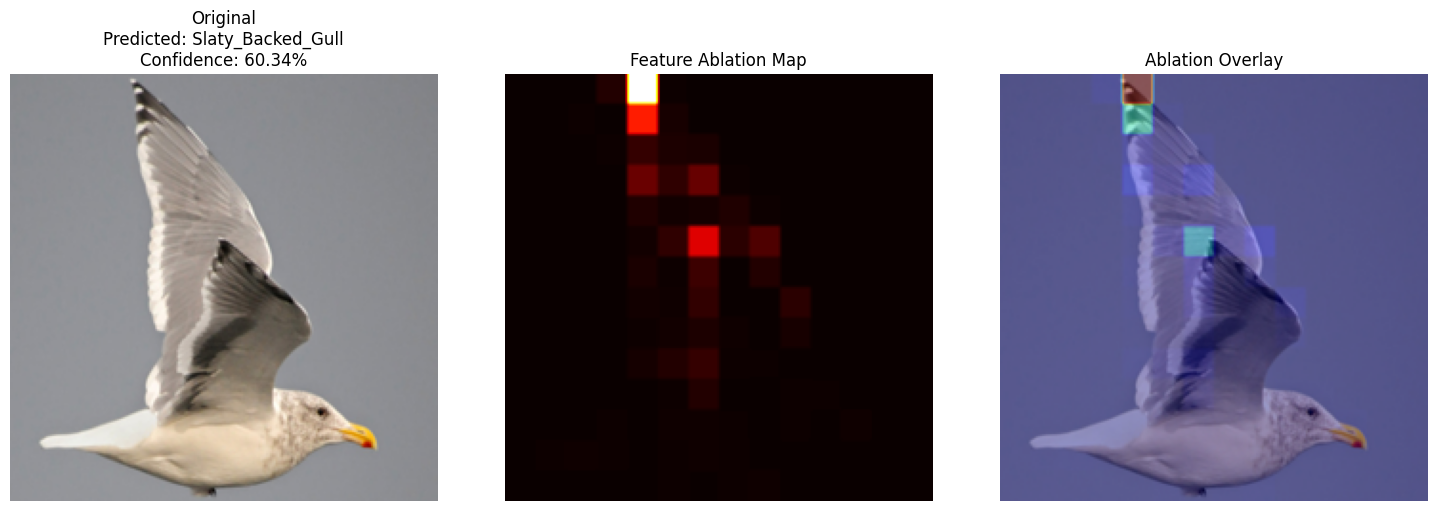

In [ ]:
import torch
import torch.nn as nn
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import timm
import os
from typing import Tuple, Optional
from torchvision import transforms
from captum.attr import FeatureAblation
from datetime import datetime

# -------------------------------
# 1) Model Definition
# -------------------------------
class ViTModified(nn.Module):
    def __init__(self, num_classes: int = 2, pretrained: bool = True):
        super().__init__()
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=pretrained)
        num_ftrs = self.vit.head.in_features
        self.vit.head = nn.Linear(num_ftrs, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.vit(x)

# -------------------------------
# 2) Feature Ablation Analyzer (With Patch-Based Masking)
# -------------------------------
class FeatureAblationAnalyzer:
    def __init__(self,
                 model: nn.Module,
                 class_names: list,
                 save_dir: str = None,
                 device: str = 'cuda' if torch.cuda.is_available() else 'cpu'):
        """
        A class to analyze the model's predictions using Feature Ablation from Captum.
        """
        self.model = model.to(device)
        self.device = device
        self.class_names = class_names
        self.save_dir = save_dir
        if save_dir:
            os.makedirs(save_dir, exist_ok=True)

        # Preprocessing transform
        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
        ])

        # Initialize Feature Ablation
        self.feature_ablator = FeatureAblation(self.model)

    def preprocess_image(self, image_path: str) -> Tuple[torch.Tensor, np.ndarray]:
        """
        Preprocess image and return both tensor and original image (as numpy).
        """
        # Open image, convert to RGB, resize for visualization
        original_image = Image.open(image_path).convert("RGB")
        original_image = original_image.resize((224, 224))
        original_np = np.array(original_image)

        # Transform to model input
        image_tensor = self.transform(original_image).unsqueeze(0).to(self.device)
        return image_tensor, original_np

    def generate_patch_feature_mask(self, image_size: int = 224, patch_size: int = 16):
        """
        Generate a feature mask that groups pixels into patches.
        - Each patch will be ablated together instead of individual pixels.
        """
        num_patches = image_size // patch_size
        mask = torch.zeros((1, image_size, image_size), dtype=torch.long)
        feature_id = 0
        for i in range(0, image_size, patch_size):
            for j in range(0, image_size, patch_size):
                mask[:, i:i+patch_size, j:j+patch_size] = feature_id
                feature_id += 1
        return mask.to(self.device)

    def generate_ablation_attribution(self, image_tensor: torch.Tensor) -> Tuple[np.ndarray, int, float]:
        """
        Generate Feature Ablation attribution map with confidence score.
        """
        self.model.eval()

        # Baseline can be zeros or any reference of the same shape
        baseline = torch.zeros_like(image_tensor).to(self.device)

        # 1. Get model output, predicted class, confidence
        with torch.no_grad():
            output = self.model(image_tensor)
            probabilities = torch.nn.functional.softmax(output, dim=1)
            confidence_score = torch.max(probabilities).item()
            pred_class = output.argmax().item()

        # 2. Compute feature ablation attributions (With Patch-Based Masking)
        patch_feature_mask = self.generate_patch_feature_mask(image_size=224, patch_size=16)
        try:
            attributions = self.feature_ablator.attribute(
                inputs=image_tensor,
                baselines=baseline,
                target=pred_class,
                feature_mask=patch_feature_mask
            )

            # Average over 3 color channels and take absolute value for visualization
            attributions = attributions.detach().cpu().numpy()
            attributions = np.mean(np.abs(attributions), axis=1)
            attributions = attributions.squeeze()

            # Resize if needed (already 224x224)
            attributions = cv2.resize(attributions, (224, 224))

            # Normalize 0-1
            attributions = (attributions - attributions.min()) / (attributions.max() - attributions.min() + 1e-8)

            # Apply a small blur for smoothing
            attributions = cv2.GaussianBlur(attributions, (3, 3), 0)

        except Exception as e:
            print(f"Error generating attribution: {str(e)}")
            # Fallback: uniform map
            attributions = np.ones((224, 224), dtype=np.float32) * 0.5

        return attributions, pred_class, confidence_score

    def create_overlay(self, original_image: np.ndarray, attributions: np.ndarray) -> np.ndarray:
        """
        Create a heatmap overlay on the original image.
        """
        attribution_map = np.uint8(attributions * 255)
        heatmap = cv2.applyColorMap(attribution_map, cv2.COLORMAP_JET)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
        overlay = cv2.addWeighted(original_image, 0.6, heatmap, 0.4, 0)
        return overlay

    def visualize_attribution(self, image_path: str):
        """
        Visualize original image, ablation attribution, and overlay.
        """
        image_tensor, original_image = self.preprocess_image(image_path)
        attributions, pred_class, confidence = self.generate_ablation_attribution(image_tensor)
        overlay_image = self.create_overlay(original_image, attributions)

        # Plot results
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        axes[0].imshow(original_image)
        axes[0].set_title(f"Original\nPredicted: {self.class_names[pred_class]}\nConfidence: {confidence:.2%}")
        axes[0].axis('off')

        axes[1].imshow(attributions, cmap='hot')
        axes[1].set_title('Feature Ablation Map')
        axes[1].axis('off')

        axes[2].imshow(overlay_image)
        axes[2].set_title('Ablation Overlay')
        axes[2].axis('off')

        plt.tight_layout()
        plt.show()

# -------------------------------
# 3) Main Script
# -------------------------------
if __name__ == "__main__":
    # Load the model
    model = ViTModified()
    model.load_state_dict(torch.load(
        '/content/drive/My Drive/FYP/VIT2_HQ2_20241224/best_model_vit_20241224.pth',
        map_location='cuda' if torch.cuda.is_available() else 'cpu'
    ))

    # Class names
    class_names = ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']

    # Save directory
    save_dir = '/content/drive/My Drive/FYP/FeatureAblation_Results'

    # Initialize analyzer
    analyzer = FeatureAblationAnalyzer(model=model, class_names=class_names, save_dir=save_dir)

    # Analyze one test image
    test_image = "/content/drive/My Drive/FYP/Dataset/HQ3/train/Slaty_Backed_Gull/011sm.jpg"
    analyzer.visualize_attribution(test_image)


In [ ]:
import torch
import torch.nn as nn
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import timm
import os
from typing import Tuple, Optional
from torchvision import transforms

class ViTModified(nn.Module):
    def __init__(self, num_classes: int = 2, pretrained: bool = True):
        super().__init__()
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=pretrained)
        num_ftrs = self.vit.head.in_features
        self.vit.head = nn.Linear(num_ftrs, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.vit(x)

class SaliencyAnalyzer:
    def __init__(self, model: nn.Module, class_names: list, device: str = 'cuda' if torch.cuda.is_available() else 'cpu'):
        self.model = model.to(device)
        self.device = device
        self.class_names = class_names
        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
        ])

    def preprocess_image(self, image_path: str) -> Tuple[torch.Tensor, np.ndarray]:
        """Preprocess image and return both tensor and original image."""
        # Load and resize original image
        original_image = Image.open(image_path).convert("RGB")
        original_image = original_image.resize((224, 224))
        original_np = np.array(original_image)

        # Transform image for model
        image_tensor = self.transform(original_image).unsqueeze(0).to(self.device)
        return image_tensor, original_np

    def generate_enhanced_saliency(self, image_tensor: torch.Tensor) -> Tuple[np.ndarray, int, float]:
        """Generate enhanced saliency map with confidence score."""
        self.model.eval()
        image_tensor.requires_grad_()

        # Forward pass
        output = self.model(image_tensor)
        probabilities = torch.nn.functional.softmax(output, dim=1)
        confidence_score = torch.max(probabilities).item()
        pred_class = output.argmax().item()

        # Calculate gradients
        self.model.zero_grad()
        output[0, pred_class].backward()

        # Generate saliency map
        saliency = image_tensor.grad.abs()

        # Enhanced aggregation across color channels
        saliency_rgb = saliency.squeeze().cpu().numpy()

        # Weight channels differently to enhance visualization
        weighted_saliency = (saliency_rgb[0] * 0.4 +
                           saliency_rgb[1] * 0.4 +
                           saliency_rgb[2] * 0.2)

        # Apply Gaussian blur to smooth the saliency map
        weighted_saliency = cv2.GaussianBlur(weighted_saliency, (3, 3), 0)

        # Normalize saliency map
        weighted_saliency = (weighted_saliency - weighted_saliency.min()) / (
            weighted_saliency.max() - weighted_saliency.min() + 1e-8)

        return weighted_saliency, pred_class, confidence_score

    def create_overlay(self, original_image: np.ndarray, saliency: np.ndarray,
                      alpha: float = 0.7, colormap: int = cv2.COLORMAP_JET) -> np.ndarray:
        """Create colored overlay of saliency map on original image."""
        # Convert saliency to heatmap
        saliency_map = np.uint8(saliency * 255)
        heatmap = cv2.applyColorMap(saliency_map, colormap)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

        # Create overlay
        overlay = cv2.addWeighted(original_image, alpha, heatmap, 1 - alpha, 0)
        return overlay

    def visualize_saliency(self, image_path: str,
                          save_path: Optional[str] = None,
                          figure_size: Tuple[int, int] = (15, 5)):
        """Visualize original image, saliency map, and overlay."""
        # Process image
        image_tensor, original_image = self.preprocess_image(image_path)
        saliency, pred_class, confidence = self.generate_enhanced_saliency(image_tensor)

        # Create overlay
        overlay_image = self.create_overlay(original_image, saliency)

        # Visualization
        fig, axes = plt.subplots(1, 3, figsize=figure_size)

        # Original image
        axes[0].imshow(original_image)
        axes[0].set_title(f"Original\nPredicted: {self.class_names[pred_class]}\nConfidence: {confidence:.2%}")
        axes[0].axis('off')

        # Saliency map
        axes[1].imshow(saliency, cmap='hot')
        axes[1].set_title('Saliency Map')
        axes[1].axis('off')

        # Overlay
        axes[2].imshow(overlay_image)
        axes[2].set_title('Overlay Visualization')
        axes[2].axis('off')

        plt.tight_layout()

        if save_path:
            plt.savefig(save_path, bbox_inches='tight', dpi=300)
            plt.close()
        else:
            plt.show()

def analyze_dataset(analyzer: SaliencyAnalyzer, test_folder: str):
    """Process all images in a test folder."""
    for root, _, files in os.walk(test_folder):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                image_path = os.path.join(root, file)
                print(f"Processing: {image_path}")
                analyzer.visualize_saliency(image_path)

# Example usage
if __name__ == "__main__":
    # Initialize model and analyzer
    model = ViTModified()
    model.load_state_dict(torch.load('/content/drive/My Drive/FYP/VIT2_HQ2_20241224/best_model_vit_20241224.pth',
                                   map_location='cpu'))
    class_names = ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']

    analyzer = SaliencyAnalyzer(model, class_names)

    # Analyze test dataset
    test_folder = '/content/drive/My Drive/FYP/Dataset/HQ2/test'
    analyze_dataset(analyzer, test_folder)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
!pip install captum

In [ ]:
import torch
import torch.nn as nn
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import timm
import os
from typing import Tuple, Optional
from torchvision import transforms
from captum.attr import DeepLift
from datetime import datetime

class ViTModified(nn.Module):
    def __init__(self, num_classes: int = 2, pretrained: bool = True):
        super().__init__()
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=pretrained)
        num_ftrs = self.vit.head.in_features
        self.vit.head = nn.Linear(num_ftrs, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.vit(x)

class DeepLIFTAnalyzer:
    def __init__(self, model: nn.Module, class_names: list,
                 save_dir: str = None,
                 device: str = 'cuda' if torch.cuda.is_available() else 'cpu'):
        self.model = model.to(device)
        self.device = device
        self.class_names = class_names
        self.save_dir = save_dir
        if save_dir:
            os.makedirs(save_dir, exist_ok=True)

        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
        ])
        self.deep_lift = DeepLift(self.model)

class DeepLIFTAnalyzer:
    def __init__(self, model: nn.Module, class_names: list,
                 save_dir: str = None,
                 device: str = 'cuda' if torch.cuda.is_available() else 'cpu'):
        self.model = model.to(device)
        self.device = device
        self.class_names = class_names
        self.save_dir = save_dir
        if save_dir:
            os.makedirs(save_dir, exist_ok=True)

        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
        ])
        self.deep_lift = DeepLift(self.model)

    def preprocess_image(self, image_path: str) -> Tuple[torch.Tensor, np.ndarray]:
        """Preprocess image and return both tensor and original image."""
        original_image = Image.open(image_path).convert("RGB")
        original_image = original_image.resize((224, 224))
        original_np = np.array(original_image)

        image_tensor = self.transform(original_image).unsqueeze(0).to(self.device)
        return image_tensor, original_np

    def generate_deeplift_attribution(self, image_tensor: torch.Tensor) -> Tuple[np.ndarray, int, float]:
        """Generate DeepLIFT attribution map with confidence score."""
        self.model.eval()

        baseline = torch.zeros_like(image_tensor).to(self.device)

        with torch.no_grad():
            output = self.model(image_tensor)
            probabilities = torch.nn.functional.softmax(output, dim=1)
            confidence_score = torch.max(probabilities).item()
            pred_class = output.argmax().item()

        try:
            attribution = self.deep_lift.attribute(
                image_tensor,
                baselines=baseline,
                target=pred_class,
                return_convergence_delta=False
            )

            attribution = attribution.detach().cpu().numpy()
            attribution = np.mean(np.abs(attribution), axis=1)
            attribution = attribution.squeeze()
            attribution = cv2.resize(attribution, (224, 224))
            attribution = (attribution - attribution.min()) / (attribution.max() - attribution.min() + 1e-8)
            attribution = cv2.GaussianBlur(attribution, (3, 3), 0)

        except Exception as e:
            print(f"Error generating attribution: {str(e)}")
            attribution = np.ones((224, 224)) * 0.5

        return attribution, pred_class, confidence_score

    def create_overlay(self, original_image: np.ndarray, attribution: np.ndarray,
                      alpha: float = 0.7, colormap: int = cv2.COLORMAP_JET) -> np.ndarray:
        """Create colored overlay of attribution map on original image."""
        # Enhance the attribution map contrast
        attribution_map = np.uint8(attribution * 255)

        # # Apply contrast enhancement
        # clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
        # attribution_map = clahe.apply(attribution_map)

        # Create more vibrant heatmap
        heatmap = cv2.applyColorMap(attribution_map, colormap)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

        # USE THIS LINE TO Increase heatmap intensity
        # heatmap = cv2.addWeighted(heatmap, 1.2, np.zeros_like(heatmap), 0, 0)

        # Create overlay with adjusted alpha for better visibility
        overlay = cv2.addWeighted(original_image, alpha, heatmap, 1.0 - alpha, 0)
        return overlay

    def visualize_attribution(self, image_path: str,
                            save_path: Optional[str] = None,
                            figure_size: Tuple[int, int] = (15, 5)):
        """Visualize original image, DeepLIFT attribution, and overlay."""
        image_tensor, original_image = self.preprocess_image(image_path)
        attribution, pred_class, confidence = self.generate_deeplift_attribution(image_tensor)
        overlay_image = self.create_overlay(original_image, attribution)

        # Create figure with larger size for better visibility
        fig, axes = plt.subplots(1, 3, figsize=figure_size)

        # Original image
        axes[0].imshow(original_image)
        axes[0].set_title(f"Original\nPredicted: {self.class_names[pred_class]}\nConfidence: {confidence:.2%}",
                         fontsize=12, pad=10)
        axes[0].axis('off')

        # Attribution map with enhanced colormap
        axes[1].imshow(attribution, cmap='hot')
        axes[1].set_title('DeepLIFT Attribution Map', fontsize=12, pad=10)
        axes[1].axis('off')

        # Enhanced overlay
        axes[2].imshow(overlay_image)
        axes[2].set_title('DeepLIFT Overlay', fontsize=12, pad=10)
        axes[2].axis('off')

        plt.tight_layout()

        # Save if requested
        if save_path or self.save_dir:
            if self.save_dir:
                class_folder = os.path.join(self.save_dir, self.class_names[pred_class])
                os.makedirs(class_folder, exist_ok=True)

                base_name = os.path.splitext(os.path.basename(image_path))[0]
                timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
                save_path = os.path.join(class_folder, f"{base_name}_deeplift_{timestamp}.png")

            plt.savefig(save_path, bbox_inches='tight', dpi=300)

        # Always display the plot
        plt.show()
        plt.close()

def analyze_dataset(analyzer: DeepLIFTAnalyzer, test_folder: str, max_images: int = None):
    """Process images in test folder up to max_images per class."""
    # Get all class folders
    class_folders = [d for d in os.listdir(test_folder)
                    if os.path.isdir(os.path.join(test_folder, d))]

    for class_folder in class_folders:
        print(f"\nProcessing class: {class_folder}")
        class_path = os.path.join(test_folder, class_folder)

        # Get all images in the class folder
        images = [f for f in os.listdir(class_path)
                 if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

        # Limit number of images if specified
        if max_images:
            images = images[:max_images]

        for image in images:
            image_path = os.path.join(class_path, image)
            print(f"Processing: {image_path}")
            analyzer.visualize_attribution(image_path)
            print(f"Visualization complete for: {image}")

if __name__ == "__main__":
    # Initialize model and analyzer
    model = ViTModified()
    model.load_state_dict(torch.load('/content/drive/My Drive/FYP/VIT2_HQ2_20241224/best_model_vit_20241224.pth',
                                   map_location='cpu'))
    class_names = ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']

    # Set up save directory in Google Drive
    save_dir = '/content/drive/My Drive/FYP/DeepLIFT_Results'

    analyzer = DeepLIFTAnalyzer(model, class_names, save_dir=save_dir)

    # Analyze test dataset with maximum 5 images per class
    test_folder = '/content/drive/My Drive/FYP/Dataset/HQ3/train'
    analyze_dataset(analyzer, test_folder, max_images=15)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install captum

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 21.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 58.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 43.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 40.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 67.1 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling 

In [ ]:
import torch
import torch.nn as nn
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import timm
import os
from typing import Tuple, Optional, Dict, List
from torchvision import transforms
from captum.attr import DeepLift
from datetime import datetime
import pandas as pd  # <-- for saving results to CSV

class ViTModified(nn.Module):
    def __init__(self, num_classes: int = 2, pretrained: bool = True):
        super().__init__()
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=pretrained)
        num_ftrs = self.vit.head.in_features
        self.vit.head = nn.Linear(num_ftrs, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.vit(x)

class DeepLIFTAnalyzer:
    def __init__(self,
                 model: nn.Module,
                 class_names: list,
                 save_dir: str = None,
                 device: str = 'cuda' if torch.cuda.is_available() else 'cpu',
                 top_saliency_percent: float = 0.2,
                 csv_results: bool = True):
        """
        Args:
            model: Trained PyTorch model (e.g., ViT).
            class_names: List of class labels.
            save_dir: Directory where images/CSV will be saved.
            device: 'cuda' or 'cpu'.
            top_saliency_percent: Keep top X% of saliency for region analysis.
            csv_results: Whether to save region metrics to CSV.
        """
        self.model = model.to(device)
        self.device = device
        self.class_names = class_names
        self.save_dir = save_dir
        if save_dir:
            os.makedirs(save_dir, exist_ok=True)

        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
        ])
        self.deep_lift = DeepLift(self.model)

        self.top_saliency_percent = top_saliency_percent
        self.csv_results = csv_results
        self.results_list = []  # Will hold metrics for CSV saving

    def preprocess_image(self, image_path: str) -> Tuple[torch.Tensor, np.ndarray]:
        """Preprocess image and return both tensor and original (224x224) image array."""
        original_image = Image.open(image_path).convert("RGB")
        original_image = original_image.resize((224, 224))
        original_np = np.array(original_image)

        image_tensor = self.transform(original_image).unsqueeze(0).to(self.device)
        return image_tensor, original_np

    def generate_deeplift_attribution(self,
                                      image_tensor: torch.Tensor
                                     ) -> Tuple[np.ndarray, int, float]:
        """
        Generate DeepLIFT attribution map with confidence score.
        Returns:
            attribution: [224x224] saliency map, normalized [0..1]
            pred_class: predicted class index
            confidence_score: predicted class confidence
        """
        self.model.eval()
        baseline = torch.zeros_like(image_tensor).to(self.device)

        with torch.no_grad():
            output = self.model(image_tensor)
            probabilities = torch.nn.functional.softmax(output, dim=1)
            confidence_score = torch.max(probabilities).item()
            pred_class = output.argmax().item()

        try:
            attribution = self.deep_lift.attribute(
                image_tensor,
                baselines=baseline,
                target=pred_class,
                return_convergence_delta=False
            )

            # Convert to NumPy and aggregate across channels
            attribution = attribution.detach().cpu().numpy()
            attribution = np.mean(np.abs(attribution), axis=1)  # shape => [1, H, W]
            attribution = attribution.squeeze()                 # => [H, W]

            # Normalize and smooth
            attribution = (attribution - attribution.min()) / (attribution.max() - attribution.min() + 1e-8)
            attribution = cv2.GaussianBlur(attribution, (3, 3), 0)

        except Exception as e:
            print(f"Error generating attribution: {str(e)}")
            # Fallback: a constant mid-level saliency
            attribution = np.ones((224, 224), dtype=np.float32) * 0.5

        return attribution, pred_class, confidence_score

    def create_overlay(self,
                       original_image: np.ndarray,
                       attribution: np.ndarray,
                       alpha: float = 0.7,
                       colormap: int = cv2.COLORMAP_JET) -> np.ndarray:
        """Create colored overlay of attribution map on the original image."""
        # Convert to 8-bit for colormap
        attribution_map = np.uint8(attribution * 255)
        heatmap = cv2.applyColorMap(attribution_map, colormap)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

        # Merge with original image
        overlay = cv2.addWeighted(original_image, alpha, heatmap, 1.0 - alpha, 0)
        return overlay

    def threshold_saliency_map(self, saliency: np.ndarray) -> np.ndarray:
        """
        Keep the top X% of the saliency map.
        Returns a binary mask [224x224], 1=most salient, 0=otherwise.
        """
        flat = saliency.flatten()
        k = int(len(flat) * self.top_saliency_percent)
        k = max(1, k)  # ensure at least 1
        topk_vals = np.partition(flat, -k)[-k:]  # get top k
        threshold = topk_vals.min()
        # Create mask
        mask = (saliency >= threshold).astype(np.uint8)
        return mask

    def measure_saliency_regions(self, mask: np.ndarray) -> Dict[str, float]:
        """
        Given a binary mask of salient regions, measure:
            - # of distinct salient blobs
            - total salient area
            - average bounding box area
            - average solidity (optional)
        Returns a dict of metrics.
        """
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return {
                "num_salient_blobs": 0,
                "total_salient_area": 0.0,
                "avg_bbox_area": 0.0
            }

        total_area = 0
        bbox_areas = []

        for c in contours:
            area = cv2.contourArea(c)
            total_area += area
            x, y, w, h = cv2.boundingRect(c)
            bbox_areas.append(w * h)

        return {
            "num_salient_blobs": len(contours),
            "total_salient_area": float(total_area),
            "avg_bbox_area": float(np.mean(bbox_areas)) if bbox_areas else 0.0
        }

    def visualize_attribution(self,
                              image_path: str,
                              save_path: Optional[str] = None,
                              figure_size: Tuple[int, int] = (15, 5)) -> Dict[str, float]:
        """
        Visualize original image, DeepLIFT attribution, overlay, and return region metrics.
        If csv_results=True, we'll store the metrics in self.results_list for later saving.
        """
        image_tensor, original_image = self.preprocess_image(image_path)
        attribution, pred_class, confidence = self.generate_deeplift_attribution(image_tensor)
        overlay_image = self.create_overlay(original_image, attribution)

        # Threshold saliency => measure region metrics
        mask = self.threshold_saliency_map(attribution)
        region_metrics = self.measure_saliency_regions(mask)

        # Create figure
        fig, axes = plt.subplots(1, 4, figsize=figure_size)

        # Original image
        axes[0].imshow(original_image)
        axes[0].set_title(
            f"Original\nPredicted: {self.class_names[pred_class]}\nConfidence: {confidence:.2%}",
            fontsize=12
        )
        axes[0].axis('off')

        # Attribution map
        axes[1].imshow(attribution, cmap='hot')
        axes[1].set_title('DeepLIFT Attribution Map', fontsize=12)
        axes[1].axis('off')

        # Overlay
        axes[2].imshow(overlay_image)
        axes[2].set_title('DeepLIFT Overlay', fontsize=12)
        axes[2].axis('off')

        # Binary mask overlay
        mask_rgb = cv2.cvtColor(mask*255, cv2.COLOR_GRAY2RGB)
        mask_overlay = cv2.addWeighted(original_image, 0.6, mask_rgb, 0.4, 0)
        axes[3].imshow(mask_overlay)
        axes[3].set_title('Saliency Mask Overlay', fontsize=12)
        axes[3].axis('off')

        plt.tight_layout()

        # Save figure if requested
        if save_path or self.save_dir:
            if self.save_dir:
                class_folder = os.path.join(self.save_dir, self.class_names[pred_class])
                os.makedirs(class_folder, exist_ok=True)

                base_name = os.path.splitext(os.path.basename(image_path))[0]
                timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
                save_path = os.path.join(class_folder, f"{base_name}_deeplift_{timestamp}.png")

            plt.savefig(save_path, bbox_inches='tight', dpi=300)

        plt.show()
        plt.close()

        # Optionally store metrics in a list for CSV
        if self.csv_results:
            record = {
                "image_path": image_path,
                "pred_class": self.class_names[pred_class],
                "confidence": confidence,
                "num_salient_blobs": region_metrics["num_salient_blobs"],
                "total_salient_area": region_metrics["total_salient_area"],
                "avg_bbox_area": region_metrics["avg_bbox_area"]
            }
            self.results_list.append(record)

        return region_metrics

    def save_csv_results(self, csv_name="deeplift_region_metrics.csv"):
        """Save all accumulated results to CSV."""
        if not self.csv_results:
            print("CSV saving is disabled (csv_results=False).")
            return

        if not self.results_list:
            print("No results to save. Did you run visualize_attribution on any images?")
            return

        df = pd.DataFrame(self.results_list)
        out_path = os.path.join(self.save_dir if self.save_dir else ".", csv_name)
        df.to_csv(out_path, index=False)
        print(f"Saved DeepLIFT region metrics to: {out_path}")

def analyze_dataset(analyzer: DeepLIFTAnalyzer, test_folder: str, max_images: int = None):
    """Process images in test folder up to max_images per class."""
    # Get all class folders
    class_folders = [
        d for d in os.listdir(test_folder)
        if os.path.isdir(os.path.join(test_folder, d))
    ]

    for class_folder in class_folders:
        print(f"\nProcessing class: {class_folder}")
        class_path = os.path.join(test_folder, class_folder)

        # Get all images in the class folder
        images = [
            f for f in os.listdir(class_path)
            if f.lower().endswith(('.png', '.jpg', '.jpeg'))
        ]

        # Limit number of images if specified
        if max_images:
            images = images[:max_images]

        for image in images:
            image_path = os.path.join(class_path, image)
            print(f"Processing: {image_path}")
            analyzer.visualize_attribution(image_path)
            print(f"Visualization + metrics done for: {image}")

    # Finally, save CSV with region metrics
    analyzer.save_csv_results()

if __name__ == "__main__":
    # 1) Initialize model
    model = ViTModified()
    model.load_state_dict(torch.load('/content/drive/My Drive/FYP/VIT2_HQ2_20241224/best_model_vit_20241224.pth',
                                     map_location='cpu'))
    model.eval()

    # 2) Define class names
    class_names = ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']

    # 3) Set up save directory
    save_dir = '/content/drive/My Drive/FYP/DeepLIFT_Results'

    # 4) Create analyzer
    #    - top_saliency_percent=0.2 => keep top 20% of saliency for region analysis
    #    - csv_results=True => store metrics in CSV
    analyzer = DeepLIFTAnalyzer(
        model=model,
        class_names=class_names,
        save_dir=save_dir,
        top_saliency_percent=0.2,
        csv_results=True
    )

    # 5) Analyze test dataset with maximum 15 images per class
    test_folder = '/content/drive/My Drive/FYP/Dataset/HQ3/train'
    analyze_dataset(analyzer, test_folder, max_images=15)


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import torch
import torch.nn as nn
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import timm
import os
from typing import Tuple, Optional
from torchvision import transforms
from captum.attr import DeepLift

class ViTModified(nn.Module):
    def __init__(self, num_classes: int = 2, pretrained: bool = True):
        super().__init__()
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=pretrained)
        num_ftrs = self.vit.head.in_features
        self.vit.head = nn.Linear(num_ftrs, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.vit(x)

class DeepLIFTAnalyzer:
    def __init__(self, model: nn.Module, class_names: list, device: str = 'cuda' if torch.cuda.is_available() else 'cpu'):
        self.model = model.to(device)
        self.device = device
        self.class_names = class_names
        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
        ])
        self.deep_lift = DeepLift(self.model)

    def preprocess_image(self, image_path: str) -> Tuple[torch.Tensor, np.ndarray]:
        """Preprocess image and return both tensor and original image."""
        original_image = Image.open(image_path).convert("RGB")
        original_image = original_image.resize((224, 224))
        original_np = np.array(original_image)

        image_tensor = self.transform(original_image).unsqueeze(0).to(self.device)
        return image_tensor, original_np

    def generate_deeplift_attribution(self, image_tensor: torch.Tensor) -> Tuple[np.ndarray, int, float]:
        """Generate DeepLIFT attribution map with confidence score."""
        self.model.eval()

        # Create baseline (zero tensor)
        baseline = torch.zeros_like(image_tensor).to(self.device)

        # Get prediction and confidence
        with torch.no_grad():
            output = self.model(image_tensor)
            probabilities = torch.nn.functional.softmax(output, dim=1)
            confidence_score = torch.max(probabilities).item()
            pred_class = output.argmax().item()

        # Generate attribution
        try:
            attribution = self.deep_lift.attribute(
                image_tensor,
                baselines=baseline,
                target=pred_class,
                return_convergence_delta=False
            )

            # Properly detach and convert to numpy
            attribution = attribution.detach().cpu().numpy()

            # Process the attribution map for visualization
            attribution = np.mean(np.abs(attribution), axis=1)  # Average across channels
            attribution = attribution.squeeze()

            # Resize attribution map to match image size (14x14 -> 224x224)
            attribution = cv2.resize(attribution, (224, 224))

            # Normalize attribution map
            attribution = (attribution - attribution.min()) / (attribution.max() - attribution.min() + 1e-8)

            # Apply Gaussian blur for smoothing
            attribution = cv2.GaussianBlur(attribution, (3, 3), 0)

        except Exception as e:
            print(f"Error generating attribution: {str(e)}")
            # Return a uniform attribution map in case of error
            attribution = np.ones((224, 224)) * 0.5

        return attribution, pred_class, confidence_score

    def create_overlay(self, original_image: np.ndarray, attribution: np.ndarray,
                      alpha: float = 0.7, colormap: int = cv2.COLORMAP_JET) -> np.ndarray:
        """Create colored overlay of attribution map on original image."""
        attribution_map = np.uint8(attribution * 255)
        heatmap = cv2.applyColorMap(attribution_map, colormap)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

        overlay = cv2.addWeighted(original_image, alpha, heatmap, 1 - alpha, 0)
        return overlay

    def visualize_attribution(self, image_path: str,
                            save_path: Optional[str] = None,
                            figure_size: Tuple[int, int] = (15, 5)):
        """Visualize original image, DeepLIFT attribution, and overlay."""
        # Process image
        image_tensor, original_image = self.preprocess_image(image_path)
        attribution, pred_class, confidence = self.generate_deeplift_attribution(image_tensor)

        # Create overlay
        overlay_image = self.create_overlay(original_image, attribution)

        # Visualization
        fig, axes = plt.subplots(1, 3, figsize=figure_size)

        # Original image
        axes[0].imshow(original_image)
        axes[0].set_title(f"Original\nPredicted: {self.class_names[pred_class]}\nConfidence: {confidence:.2%}")
        axes[0].axis('off')

        # Attribution map
        axes[1].imshow(attribution, cmap='hot')
        axes[1].set_title('DeepLIFT Attribution Map')
        axes[1].axis('off')

        # Overlay
        axes[2].imshow(overlay_image)
        axes[2].set_title('DeepLIFT Overlay')
        axes[2].axis('off')

        plt.tight_layout()

        if save_path:
            plt.savefig(save_path, bbox_inches='tight', dpi=300)
            plt.close()
        else:
            plt.show()

def analyze_dataset(analyzer: DeepLIFTAnalyzer, test_folder: str):
    """Process all images in a test folder."""
    for root, _, files in os.walk(test_folder):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                image_path = os.path.join(root, file)
                print(f"Processing: {image_path}")
                analyzer.visualize_attribution(image_path)

if __name__ == "__main__":
    # Initialize model and analyzer
    model = ViTModified()
    model.load_state_dict(torch.load('/content/drive/My Drive/FYP/VIT2_HQ2_20241224/best_model_vit_20241224.pth',
                                   map_location='cpu'))
    class_names = ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']

    analyzer = DeepLIFTAnalyzer(model, class_names)

    # Analyze test dataset
    test_folder = '/content/drive/My Drive/FYP/Dataset/HQ2/train'
    analyze_dataset(analyzer, test_folder)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import torch
import torch.nn as nn
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import timm
import os
from typing import Tuple, Optional, List
from torchvision import transforms

class ViTModified(nn.Module):
    def __init__(self, num_classes: int = 2, pretrained: bool = True):
        super().__init__()
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=pretrained)
        num_ftrs = self.vit.head.in_features
        self.vit.head = nn.Linear(num_ftrs, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.vit(x)

class AttentionVisualizer:
    def __init__(self, model: nn.Module, class_names: list, device: str = 'cuda' if torch.cuda.is_available() else 'cpu'):
        self.model = model.to(device)
        self.device = device
        self.class_names = class_names
        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
        self.patch_size = 16
        self.img_size = 224

    def get_attention_maps(self, x: torch.Tensor) -> Tuple[torch.Tensor, int, float]:
        """Extract attention weights and predictions."""
        self.model.eval()
        attention_maps = []

        def attention_hook(module, inp, out):
            # qkv shape: [batch_size, num_patches + 1, 3 * (num_heads * head_dim)]
            qkv = module.qkv(inp[0])
            batch_size, num_patches, width = qkv.shape
            qkv = qkv.reshape(batch_size, num_patches, 3, module.num_heads, -1).permute(2, 0, 3, 1, 4)
            q, k, v = qkv[0], qkv[1], qkv[2]

            # Compute attention scores
            attn = (q @ k.transpose(-2, -1)) * module.scale
            attn = attn.softmax(dim=-1)  # [batch_size, num_heads, num_patches, num_patches]
            attention_maps.append(attn)

        # Register hooks for attention
        hooks = []
        for block in self.model.vit.blocks:
            hooks.append(block.attn.register_forward_hook(attention_hook))

        # Forward pass
        with torch.no_grad():
            output = self.model(x)
            probs = torch.nn.functional.softmax(output, dim=1)
            pred_class = output.argmax(dim=1).item()
            confidence = probs.max().item()

        # Remove hooks
        for hook in hooks:
            hook.remove()

        # Process attention maps
        if not attention_maps:
            raise ValueError("No attention maps were captured!")

        # Average attention across all layers and heads
        attention = torch.stack(attention_maps)
        attention = attention.mean(dim=[0, 2])  # Average across layers and heads
        attention = attention[0]  # Take the first batch item

        return attention, pred_class, confidence

    def process_attention_weights(self, attention: torch.Tensor) -> np.ndarray:
        """Process attention weights into a visualization-ready format."""
        # Remove CLS token attention
        attention = attention[1:, 1:]

        # Reshape into grid
        grid_size = int(np.sqrt(attention.shape[0]))
        attention_grid = attention.reshape(grid_size, grid_size).cpu().numpy()

        # Normalize for visualization
        attention_grid = (attention_grid - attention_grid.min()) / (
            attention_grid.max() - attention_grid.min() + 1e-8)

        return attention_grid

    def create_attention_overlay(self, image: np.ndarray, attention_map: np.ndarray,
                               alpha: float = 0.6) -> np.ndarray:
        """Create colored overlay of attention map on original image."""
        attention_map_resized = cv2.resize(attention_map, (self.img_size, self.img_size))
        heatmap = cv2.applyColorMap(np.uint8(255 * attention_map_resized), cv2.COLORMAP_JET)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

        # Ensure images are in the same format
        if len(image.shape) == 2:
            image = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
        elif image.shape[2] == 4:
            image = cv2.cvtColor(image, cv2.COLOR_RGBA2RGB)

        overlay = cv2.addWeighted(image, alpha, heatmap, 1 - alpha, 0)
        return overlay

    def visualize_attention(self, image_path: str,
                          save_path: Optional[str] = None,
                          figure_size: Tuple[int, int] = (15, 5)) -> None:
        """Visualize attention for an image."""
        try:
            # Load and preprocess image
            image = Image.open(image_path).convert('RGB')
            original_image = np.array(image.resize((self.img_size, self.img_size)))
            image_tensor = self.transform(image).unsqueeze(0).to(self.device)

            # Get attention maps and predictions
            attention, pred_class, confidence = self.get_attention_maps(image_tensor)

            # Process attention weights
            attention_grid = self.process_attention_weights(attention)

            # Create overlay
            overlay_image = self.create_attention_overlay(original_image, attention_grid)

            # Visualization
            fig, axes = plt.subplots(1, 3, figsize=figure_size)

            # Original image
            axes[0].imshow(original_image)
            axes[0].set_title(f"Original\nPredicted: {self.class_names[pred_class]}\nConfidence: {confidence:.2%}")
            axes[0].axis('off')

            # Attention map
            axes[1].imshow(attention_grid, cmap='hot')
            axes[1].set_title('Attention Map')
            axes[1].axis('off')

            # Overlay
            axes[2].imshow(overlay_image)
            axes[2].set_title('Attention Overlay')
            axes[2].axis('off')

            plt.tight_layout()

            if save_path:
                plt.savefig(save_path, bbox_inches='tight', dpi=300)
                plt.close()
            else:
                plt.show()

        except Exception as e:
            print(f"Error processing {image_path}: {str(e)}")
            import traceback
            traceback.print_exc()
            plt.close()

def analyze_dataset(visualizer: AttentionVisualizer, test_folder: str, output_folder: Optional[str] = None):
    """Process all images in a test folder."""
    os.makedirs(output_folder, exist_ok=True) if output_folder else None

    for root, _, files in os.walk(test_folder):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                image_path = os.path.join(root, file)
                print(f"Processing: {image_path}")

                if output_folder:
                    save_path = os.path.join(output_folder, f"{os.path.splitext(file)[0]}_attention.png")
                    visualizer.visualize_attention(image_path, save_path)
                else:
                    visualizer.visualize_attention(image_path)



# Example usage
if __name__ == "__main__":
    # Initialize model and visualizer
    model = ViTModified()
    model.load_state_dict(torch.load('/content/drive/My Drive/FYP/VIT2_HQ2_20241224/best_model_vit_20241224.pth', map_location='cpu'))
    class_names = ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']

    visualizer = AttentionVisualizer(model, class_names)

    # Analyze test dataset
    test_folder = '/content/drive/My Drive/FYP/Dataset/HQ2/test'
    output_folder = '/content/drive/My Drive/FYP/VITOutput'  # Optional: specify to save visualizations
    analyze_dataset(visualizer, test_folder, output_folder)

<ipython-input-14-655c84e02d5c>:183: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('/content/drive/My Drive/FYP/VIT2_HQ2_20241224/best_model

Processing: /content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull/imageRTEs.jpg
Error processing /content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull/imageRTEs.jpg: shape '[14, 14]' is invalid for input of size 38416
Processing: /content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull/iDFGmages.jpg


Traceback (most recent call last):
  File "<ipython-input-14-655c84e02d5c>", line 124, in visualize_attention
    attention_grid = self.process_attention_weights(attention)
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<ipython-input-14-655c84e02d5c>", line 86, in process_attention_weights
    attention_grid = attention.reshape(grid_size, grid_size).cpu().numpy()
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: shape '[14, 14]' is invalid for input of size 38416


Error processing /content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull/iDFGmages.jpg: shape '[14, 14]' is invalid for input of size 38416
Processing: /content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull/images.jpg


Traceback (most recent call last):
  File "<ipython-input-14-655c84e02d5c>", line 124, in visualize_attention
    attention_grid = self.process_attention_weights(attention)
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<ipython-input-14-655c84e02d5c>", line 86, in process_attention_weights
    attention_grid = attention.reshape(grid_size, grid_size).cpu().numpy()
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: shape '[14, 14]' is invalid for input of size 38416


...

Error processing /content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull/480 (11).jpeg: shape '[14, 14]' is invalid for input of size 38416
Processing: /content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull/320 (5).jpeg


Traceback (most recent call last):
  File "<ipython-input-14-655c84e02d5c>", line 124, in visualize_attention
    attention_grid = self.process_attention_weights(attention)
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<ipython-input-14-655c84e02d5c>", line 86, in process_attention_weights
    attention_grid = attention.reshape(grid_size, grid_size).cpu().numpy()
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: shape '[14, 14]' is invalid for input of size 38416


Error processing /content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull/320 (5).jpeg: shape '[14, 14]' is invalid for input of size 38416
Processing: /content/drive/My Drive/FYP/Dataset/HQ2/test/Slaty_Backed_Gull/480 (14).jpeg


Traceback (most recent call last):
  File "<ipython-input-14-655c84e02d5c>", line 124, in visualize_attention
    attention_grid = self.process_attention_weights(attention)
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<ipython-input-14-655c84e02d5c>", line 86, in process_attention_weights
    attention_grid = attention.reshape(grid_size, grid_size).cpu().numpy()
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: shape '[14, 14]' is invalid for input of size 38416


KeyboardInterrupt: 

In [ ]:
!pip install torch torchvision timm matplotlib pillow numpy opencv-python

import torch
import torch.nn as nn
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import timm
import os
from typing import Tuple, Optional
from torchvision import transforms

class ViTModified(nn.Module):
    def __init__(self, num_classes: int = 2, pretrained: bool = True):
        super().__init__()
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=pretrained)
        num_ftrs = self.vit.head.in_features
        self.vit.head = nn.Linear(num_ftrs, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.vit(x)

class AttentionVisualizer:
    def __init__(self, model: nn.Module, class_names: list, device: str = 'cuda' if torch.cuda.is_available() else 'cpu'):
        self.model = model.to(device)
        self.device = device
        self.class_names = class_names
        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
        self.patch_size = 16
        self.img_size = 224

    def get_attention_maps(self, x: torch.Tensor) -> Tuple[torch.Tensor, int, float]:
        """Extract attention weights and predictions."""
        self.model.eval()
        attention_maps = []

        def attention_hook(module, inp, out):
            qkv = module.qkv(inp[0])
            batch_size, num_patches, width = qkv.shape
            qkv = qkv.reshape(batch_size, num_patches, 3, module.num_heads, -1).permute(2, 0, 3, 1, 4)
            q, k, _ = qkv[0], qkv[1], qkv[2]

            # Compute attention scores
            attn = (q @ k.transpose(-2, -1)) * module.scale
            attn = attn.softmax(dim=-1)  # [batch_size, num_heads, num_patches, num_patches]
            attention_maps.append(attn)

        # Register hooks for attention
        hooks = []
        for block in self.model.vit.blocks:
            hooks.append(block.attn.register_forward_hook(attention_hook))

        # Forward pass
        with torch.no_grad():
            output = self.model(x)
            probs = torch.nn.functional.softmax(output, dim=1)
            pred_class = output.argmax(dim=1).item()
            confidence = probs.max().item()

        # Remove hooks
        for hook in hooks:
            hook.remove()

        if not attention_maps:
            raise ValueError("No attention maps were captured!")

        # Average attention across all layers and heads
        attention = torch.stack(attention_maps)
        attention = attention.mean(dim=[0, 2])  # Average across layers and heads
        attention = attention[0]  # Take the first batch item

        return attention, pred_class, confidence

    def process_attention_weights(self, attention: torch.Tensor) -> np.ndarray:
        """Process attention weights into a visualization-ready format."""
        attention = attention[1:, 1:]  # Remove CLS token attention
        num_patches = attention.shape[0]
        grid_size = int(np.sqrt(num_patches))

        if grid_size ** 2 != num_patches:
            raise ValueError(f"Invalid attention shape: {attention.shape}. Cannot reshape to a square grid.")

        attention_grid = attention.reshape(grid_size, grid_size).cpu().numpy()
        attention_grid = (attention_grid - attention_grid.min()) / (attention_grid.max() - attention_grid.min() + 1e-8)
        return attention_grid


    def create_attention_overlay(self, image: np.ndarray, attention_map: np.ndarray, alpha: float = 0.6) -> np.ndarray:
        """Create colored overlay of attention map on original image."""
        attention_map_resized = cv2.resize(attention_map, (self.img_size, self.img_size))
        heatmap = cv2.applyColorMap(np.uint8(255 * attention_map_resized), cv2.COLORMAP_JET)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

        if len(image.shape) == 2:
            image = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
        elif image.shape[2] == 4:
            image = cv2.cvtColor(image, cv2.COLOR_RGBA2RGB)

        overlay = cv2.addWeighted(image, alpha, heatmap, 1 - alpha, 0)
        return overlay

    def visualize_attention(self, image_path: str, save_path: Optional[str] = None, figure_size: Tuple[int, int] = (15, 5)) -> None:
        """Visualize attention for an image."""
        try:
            image = Image.open(image_path).convert('RGB')
            original_image = np.array(image.resize((self.img_size, self.img_size)))
            image_tensor = self.transform(image).unsqueeze(0).to(self.device)

            attention, pred_class, confidence = self.get_attention_maps(image_tensor)
            attention_grid = self.process_attention_weights(attention)
            overlay_image = self.create_attention_overlay(original_image, attention_grid)

            fig, axes = plt.subplots(1, 3, figsize=figure_size)
            axes[0].imshow(original_image)
            axes[0].set_title(f"Original\nPredicted: {self.class_names[pred_class]}\nConfidence: {confidence:.2%}")
            axes[0].axis('off')

            axes[1].imshow(attention_grid, cmap='hot')
            axes[1].set_title('Attention Map')
            axes[1].axis('off')

            axes[2].imshow(overlay_image)
            axes[2].set_title('Attention Overlay')
            axes[2].axis('off')

            plt.tight_layout()

            if save_path:
                plt.savefig(save_path, bbox_inches='tight', dpi=300)
                plt.close()
            else:
                plt.show()
        except Exception as e:
            print(f"Error processing {image_path}: {str(e)}")
            import traceback
            traceback.print_exc()
            plt.close()

def analyze_dataset(visualizer: AttentionVisualizer, test_folder: str, output_folder: Optional[str] = None):
    """Process all images in a test folder."""
    os.makedirs(output_folder, exist_ok=True) if output_folder else None

    for root, _, files in os.walk(test_folder):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                image_path = os.path.join(root, file)
                print(f"Processing: {image_path}")

                if output_folder:
                    save_path = os.path.join(output_folder, f"{os.path.splitext(file)[0]}_attention.png")
                    visualizer.visualize_attention(image_path, save_path)
                else:
                    visualizer.visualize_attention(image_path)

# Example usage
if __name__ == "__main__":
    # Initialize model and visualizer
    model = ViTModified()
    model.load_state_dict(torch.load('/content/drive/My Drive/FYP/VIT2_HQ2_20241224/best_model_vit_20241224.pth', map_location='cpu'))
    class_names = ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']

    visualizer = AttentionVisualizer(model, class_names)

    # Analyze test dataset
    test_folder = '/content/drive/My Drive/FYP/Dataset/HQ2/test'
    output_folder = '/content/drive/My Drive/FYP/VITOutput'  # Optional: specify to save visualizations
    analyze_dataset(visualizer, test_folder, output_folder)


<ipython-input-17-450ad66a6e69>:164: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('/content/drive/My Drive/FYP/VIT2_HQ2_20241224/best_model

Processing: /content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull/imageRTEs.jpg
Error processing /content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull/imageRTEs.jpg: shape '[14, 14]' is invalid for input of size 38416
Processing: /content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull/iDFGmages.jpg


Traceback (most recent call last):
  File "<ipython-input-17-450ad66a6e69>", line 115, in visualize_attention
    attention_grid = self.process_attention_weights(attention)
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<ipython-input-17-450ad66a6e69>", line 88, in process_attention_weights
    attention_grid = attention.reshape(grid_size, grid_size).cpu().numpy()
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: shape '[14, 14]' is invalid for input of size 38416


Error processing /content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull/iDFGmages.jpg: shape '[14, 14]' is invalid for input of size 38416
Processing: /content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull/images.jpg


Traceback (most recent call last):
  File "<ipython-input-17-450ad66a6e69>", line 115, in visualize_attention
    attention_grid = self.process_attention_weights(attention)
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<ipython-input-17-450ad66a6e69>", line 88, in process_attention_weights
    attention_grid = attention.reshape(grid_size, grid_size).cpu().numpy()
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: shape '[14, 14]' is invalid for input of size 38416


...

Error processing /content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull/480 (11).jpeg: shape '[14, 14]' is invalid for input of size 38416
Processing: /content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull/320 (5).jpeg


Traceback (most recent call last):
  File "<ipython-input-17-450ad66a6e69>", line 115, in visualize_attention
    attention_grid = self.process_attention_weights(attention)
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<ipython-input-17-450ad66a6e69>", line 88, in process_attention_weights
    attention_grid = attention.reshape(grid_size, grid_size).cpu().numpy()
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: shape '[14, 14]' is invalid for input of size 38416


Error processing /content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull/320 (5).jpeg: shape '[14, 14]' is invalid for input of size 38416
Processing: /content/drive/My Drive/FYP/Dataset/HQ2/test/Slaty_Backed_Gull/480 (14).jpeg


Traceback (most recent call last):
  File "<ipython-input-17-450ad66a6e69>", line 115, in visualize_attention
    attention_grid = self.process_attention_weights(attention)
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<ipython-input-17-450ad66a6e69>", line 88, in process_attention_weights
    attention_grid = attention.reshape(grid_size, grid_size).cpu().numpy()
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: shape '[14, 14]' is invalid for input of size 38416


KeyboardInterrupt: 